# 01 — A classical color-detection pipeline

We will build a deliberately small object detector:

$$\text{image} \rightarrow \text{color mask} \rightarrow \text{morphology} \rightarrow \text{components} \rightarrow \text{boxes}$$

The target is an orange object living in a synthetic scene with uneven illumination, holes, and distractors. In other words, a normal Tuesday for classical computer vision.

By the end, you should be able to explain:

- why a color space is a representation rather than new image information;
- why fixed RGB thresholds are sensitive to illumination;
- how HSV can make a color rule easier to express;
- what erosion, dilation, opening, and closing do to a binary mask;
- how connected components turn foreground pixels into object candidates.

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

np.set_printoptions(suppress=True)
print(f"OpenCV {cv2.__version__} | NumPy {np.__version__}")

from wave_part_dual.classical_cv import mask_iou

OpenCV 4.14.0 | NumPy 2.5.4


## 1. Construct a tiny world

A synthetic scene gives us something photographs usually refuse to provide: exact ground truth. We know which pixels belong to the target, so later we can measure detection quality instead of declaring victory because a plot looks persuasive.

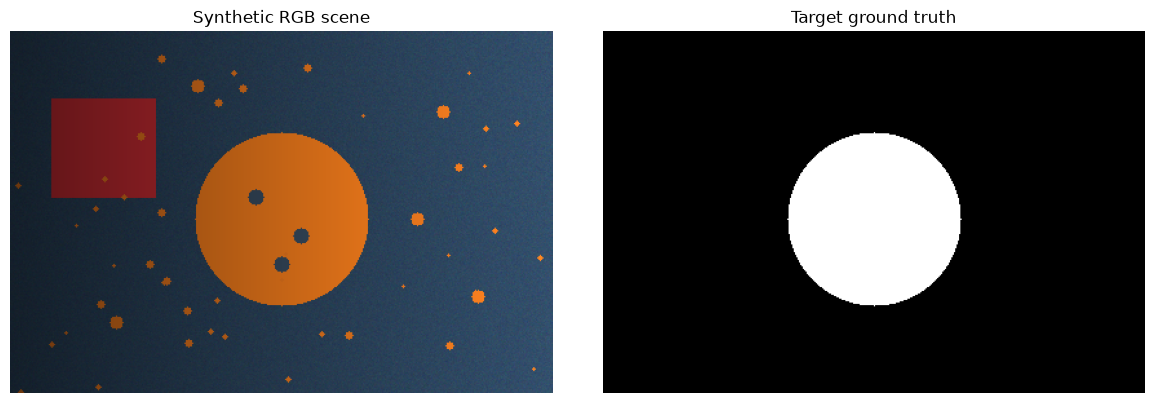

In [2]:
def make_scene(brightness: float = 1.0, seed: int = 7):
    rng = np.random.default_rng(seed)
    height, width = 280, 420

    # A mildly textured blue-gray background.
    image = np.full((height, width, 3), (45, 70, 95), dtype=np.float32)
    image += rng.normal(0, 4, image.shape)

    ground_truth = np.zeros((height, width), dtype=np.uint8)
    cv2.circle(ground_truth, (210, 145), 67, 255, thickness=-1)
    image[ground_truth > 0] = (245, 125, 28)  # RGB orange

    # A red distractor, tiny orange confetti, and a few stubborn orange blobs.
    cv2.rectangle(image, (32, 52), (112, 128), (205, 45, 52), thickness=-1)
    for _ in range(45):
        x = int(rng.integers(0, width))
        y = int(rng.integers(0, height))
        cv2.circle(image, (x, y), int(rng.integers(1, 4)), (235, 120, 30), -1)
    for center in [(145, 42), (335, 62), (362, 205), (82, 225), (315, 145)]:
        cv2.circle(image, center, 5, (235, 120, 30), thickness=-1)

    # Holes in the target simulate specular highlights or missing mask pixels.
    for center in [(190, 128), (225, 158), (210, 180)]:
        cv2.circle(image, center, 6, (55, 75, 95), thickness=-1)

    # Illumination changes from dark on the left to bright on the right.
    illumination = np.linspace(0.45, 1.15, width, dtype=np.float32)
    image *= illumination[None, :, None] * brightness
    return np.clip(image, 0, 255).astype(np.uint8), ground_truth

rgb, ground_truth = make_scene()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(rgb)
axes[0].set_title("Synthetic RGB scene")
axes[1].imshow(ground_truth, cmap="gray")
axes[1].set_title("Target ground truth")
for ax in axes:
    ax.axis("off")
plt.tight_layout()

### OpenCV's tiny practical joke: BGR

Most plotting and imaging conventions use RGB channel order. OpenCV historically reads and stores ordinary color images as **BGR**. `cv2.imread(...)` therefore needs conversion before `plt.imshow(...)`:

```python
bgr = cv2.imread(path)
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
```

Our generated image is already RGB. Forgetting which convention is active produces blue oranges and philosophical doubt.

## 2. RGB and threshold masks

An RGB pixel is a point $(R, G, B)$ in a three-dimensional cube. A simple detector defines an allowed region in that cube. `cv2.inRange` returns 255 where every channel lies inside the specified interval and 0 elsewhere.

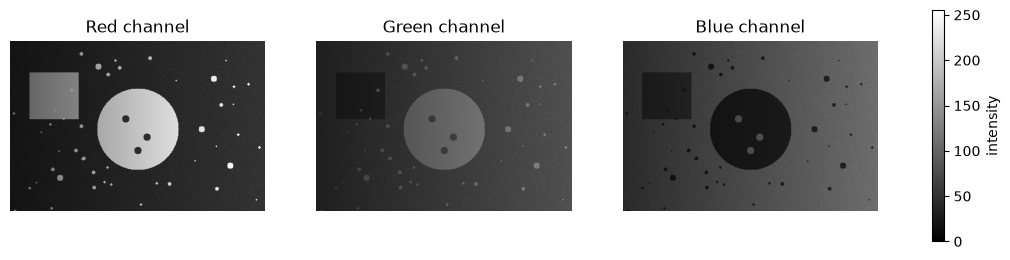

In [3]:
channels = ["red", "green", "blue"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for index, (name, ax) in enumerate(zip(channels, axes)):
    view = ax.imshow(rgb[..., index], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{name.title()} channel")
    ax.axis("off")
fig.colorbar(view, ax=axes, shrink=0.75, label="intensity");

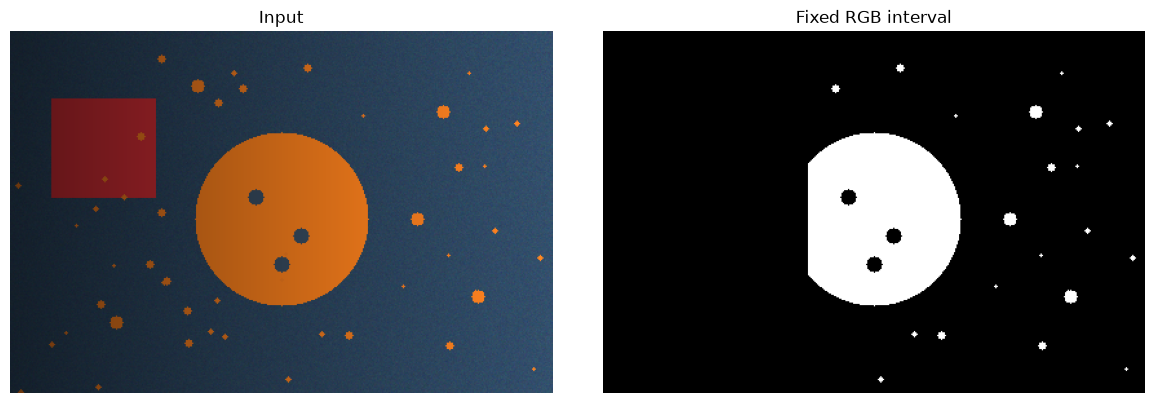

In [4]:
rgb_lower = np.array([175, 65, 10], dtype=np.uint8)
rgb_upper = np.array([255, 160, 75], dtype=np.uint8)
rgb_mask = cv2.inRange(rgb, rgb_lower, rgb_upper)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(rgb)
axes[0].set_title("Input")
axes[1].imshow(rgb_mask, cmap="gray")
axes[1].set_title("Fixed RGB interval")
for ax in axes:
    ax.axis("off")
plt.tight_layout()

The target has one nominal surface color, yet its RGB coordinates move when illumination changes. A narrow interval rejects darker target pixels; a wide interval admits more background and distractors. The representation mixes color and brightness, making the rule awkward.

RGB is not *bad*. It is simply a poor coordinate system for this particular question.

## 3. HSV: describe the rule we actually mean

HSV represents pixels using:

- **Hue**: position around the color wheel;
- **Saturation**: colorfulness versus gray;
- **Value**: brightness.

This lets us say “orange and reasonably saturated” while allowing a broad range of brightness. HSV does not create illumination invariance—shadows, clipping, and weak saturation still cause trouble—but it often makes color segmentation more robust and interpretable.

OpenCV encodes hue in `[0, 179]`, not degrees `[0, 360)`. Saturation and value use `[0, 255]`. Hue is circular, so red often requires two intervals near 0 and 179.

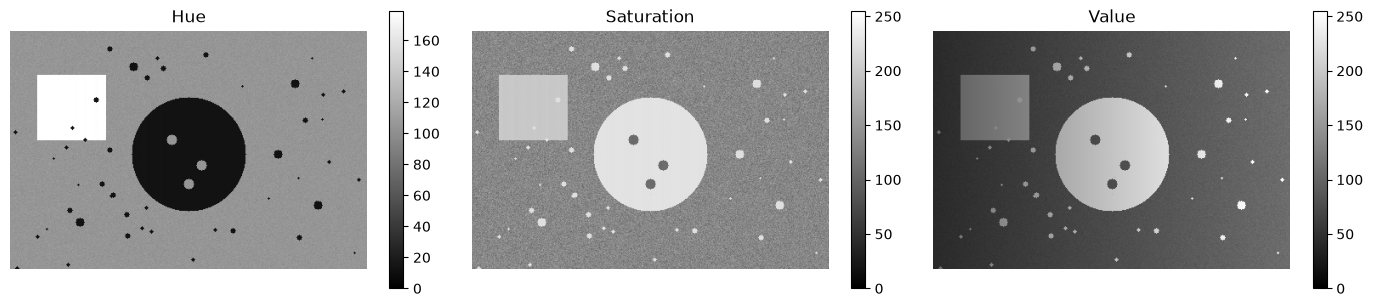

In [5]:
hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
hsv_names = ["hue", "saturation", "value"]
hsv_limits = [(0, 179), (0, 255), (0, 255)]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for index, (name, limits, ax) in enumerate(zip(hsv_names, hsv_limits, axes)):
    view = ax.imshow(hsv[..., index], cmap="gray", vmin=limits[0], vmax=limits[1])
    ax.set_title(name.title())
    ax.axis("off")
    fig.colorbar(view, ax=ax, shrink=0.75)
plt.tight_layout()

> **What does `cvtColor` do here?**
>
> It transforms each pixel independently—there is no learning and no use of neighboring pixels. After scaling RGB values, the largest channel becomes **value** (brightness), the difference between the largest and smallest channels determines **saturation** (how colorful the pixel is), and the largest channel plus the relative differences determine **hue** (where the color sits around the color wheel). OpenCV then stores hue in `0–179` and saturation/value in `0–255`. Gray pixels have almost no channel difference, so their hue is not meaningful.


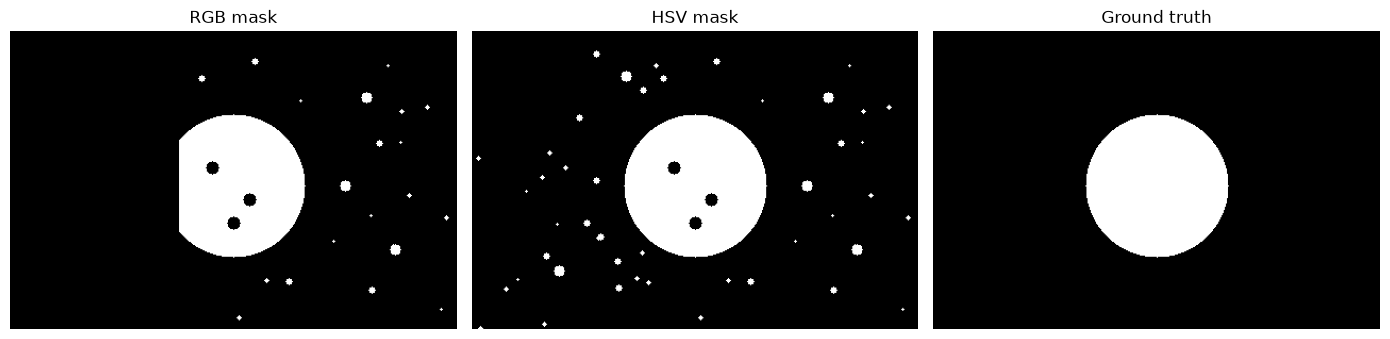

In [6]:
hsv_lower = np.array([5, 120, 35], dtype=np.uint8)
hsv_upper = np.array([22, 255, 255], dtype=np.uint8)
hsv_mask = cv2.inRange(hsv, hsv_lower, hsv_upper)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, image, title in zip(
    axes,
    [rgb_mask, hsv_mask, ground_truth],
    ["RGB mask", "HSV mask", "Ground truth"],
):
    ax.imshow(image, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()

### Quantify the masks

Intersection over Union (IoU) compares a predicted foreground set $P$ with ground truth $G$:

$$\operatorname{IoU}(P,G)=\frac{|P \cap G|}{|P \cup G|}$$

A score of 1 is perfect; 0 means the masks do not overlap.

In [7]:
print(f"RGB IoU: {mask_iou(rgb_mask, ground_truth):.3f}")
print(f"HSV IoU: {mask_iou(hsv_mask, ground_truth):.3f}")

RGB IoU: 0.881
HSV IoU: 0.906


### Practice: RGB threshold surgery

Compare several thresholds at once instead of repeatedly overwriting one mask. Each experiment changes only one bound from the baseline, so the cause of each result remains visible. IoU summarizes the complete mask, but inspect *where* the white pixels appear or disappear too.

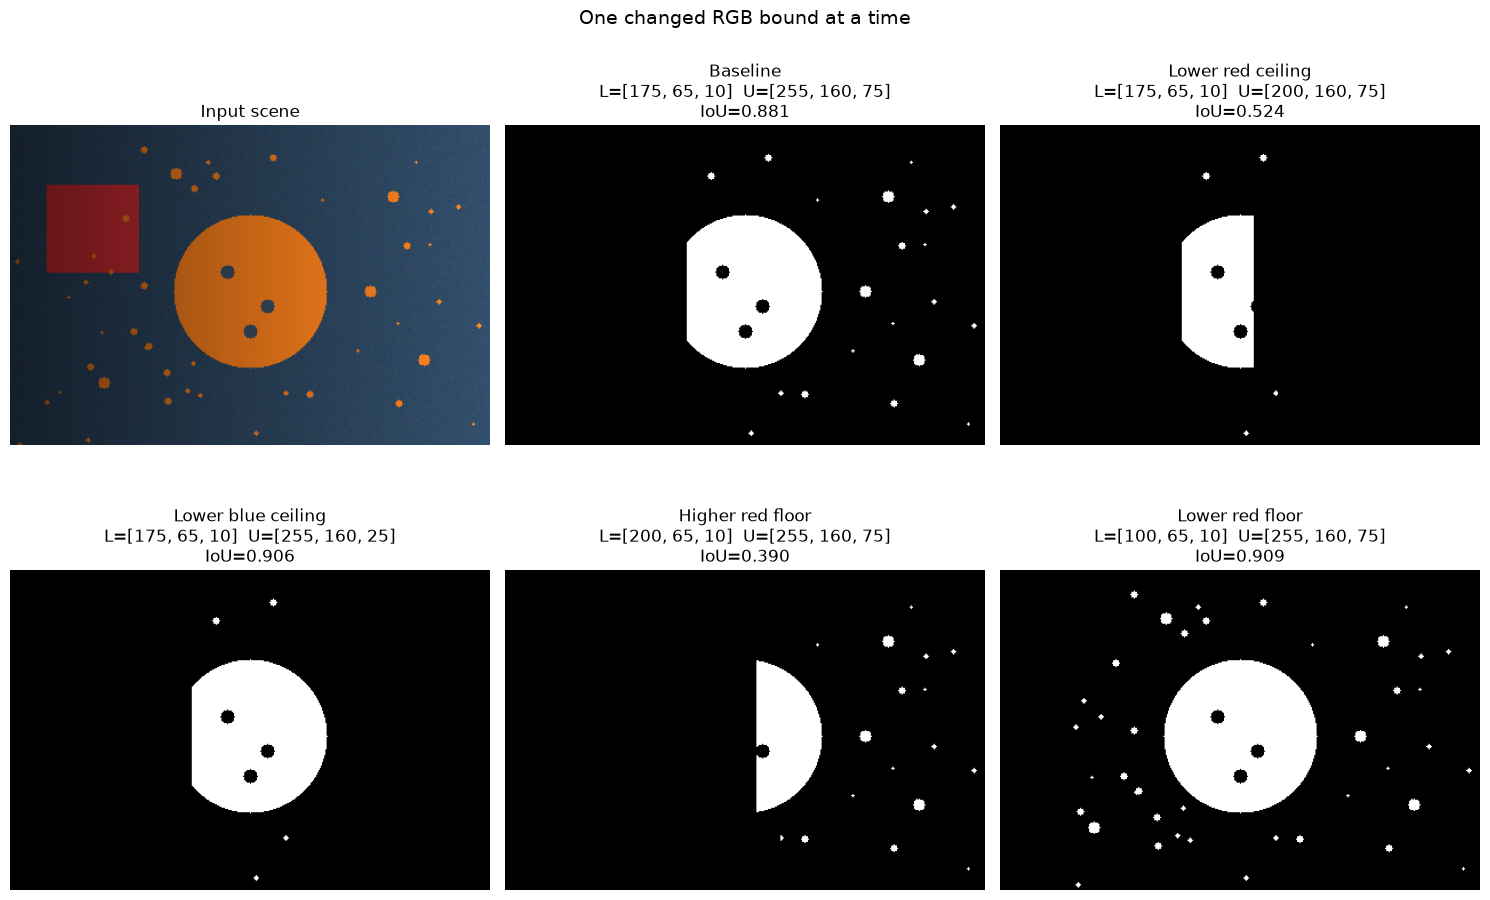

In [8]:
rgb_threshold_experiments = [
    ("Baseline", [175, 65, 10], [255, 160, 75]),
    ("Lower red ceiling", [175, 65, 10], [200, 160, 75]),
    ("Lower blue ceiling", [175, 65, 10], [255, 160, 25]),
    ("Higher red floor", [200, 65, 10], [255, 160, 75]),
    ("Lower red floor", [100, 65, 10], [255, 160, 75]),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes[0, 0].imshow(rgb)
axes[0, 0].set_title("Input scene")

for ax, (name, lower, upper) in zip(axes.flat[1:], rgb_threshold_experiments):
    lower = np.asarray(lower, dtype=np.uint8)
    upper = np.asarray(upper, dtype=np.uint8)
    candidate_mask = cv2.inRange(rgb, lower, upper)
    score = mask_iou(candidate_mask, ground_truth)
    ax.imshow(candidate_mask, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{name}\nL={lower.tolist()}  U={upper.tolist()}\nIoU={score:.3f}")

for ax in axes.flat:
    ax.axis("off")
fig.suptitle("One changed RGB bound at a time", fontsize=14)
plt.tight_layout()

> **Off-topic, but useful — why is it called morphology?**
>
> In general, *morphology* means the study of form and shape. Biology uses it for the shapes of living things; computer vision borrows it for the shapes made by pixels. Here we shrink, grow, repair, or inspect those shapes. Same word, fewer frogs.


## 4. Morphology: negotiate with the mask

Binary morphology probes a mask with a small **structuring element** (kernel):

- **erosion** keeps a foreground pixel only when the kernel fits inside foreground; objects shrink and tiny foreground noise disappears;
- **dilation** keeps a foreground pixel when the kernel touches foreground; objects grow and small gaps shrink;
- **opening** = erosion then dilation; useful for removing small foreground islands;
- **closing** = dilation then erosion; useful for filling small holes and joining narrow breaks.

Kernel shape, size, and iteration count encode assumptions about what counts as small. We use a 7×7 kernel to remove tiny specks and a larger 15×15 kernel to fill the roughly 12-pixel-wide holes—the tool must be large enough to affect the defect. Morphology is geometry with opinions.

Raw HSV IoU:   0.906
Clean mask IoU: 0.975


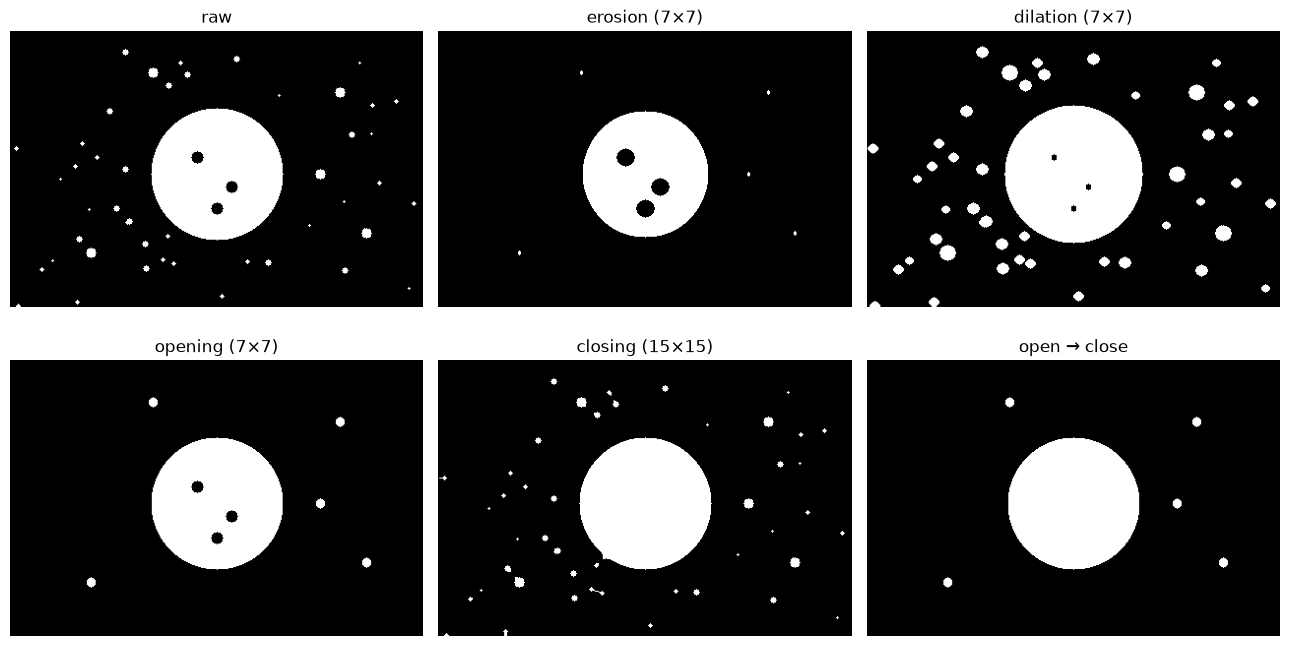

In [9]:
opening_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
closing_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
eroded = cv2.erode(hsv_mask, opening_kernel)
dilated = cv2.dilate(hsv_mask, opening_kernel)
opened = cv2.morphologyEx(hsv_mask, cv2.MORPH_OPEN, opening_kernel)
closed = cv2.morphologyEx(hsv_mask, cv2.MORPH_CLOSE, closing_kernel)
clean_mask = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, closing_kernel)

images = [hsv_mask, eroded, dilated, opened, closed, clean_mask]
titles = ["raw", "erosion (7×7)", "dilation (7×7)", "opening (7×7)", "closing (15×15)", "open → close"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, image, title in zip(axes.flat, images, titles):
    ax.imshow(image, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
print(f"Raw HSV IoU:   {mask_iou(hsv_mask, ground_truth):.3f}")
print(f"Clean mask IoU: {mask_iou(clean_mask, ground_truth):.3f}")

Opening and closing are not universally beneficial. An oversized kernel can erase small valid objects, merge nearby objects, or deform boundaries. Always relate the kernel to expected object scale.

### Practice: kernel laboratory

Compare kernel shape and size systematically. The first grid shows the actual structuring elements; the second applies opening followed by closing with the same kernel. This is intentionally different from the main pipeline, where opening and closing use sizes matched to different defects.

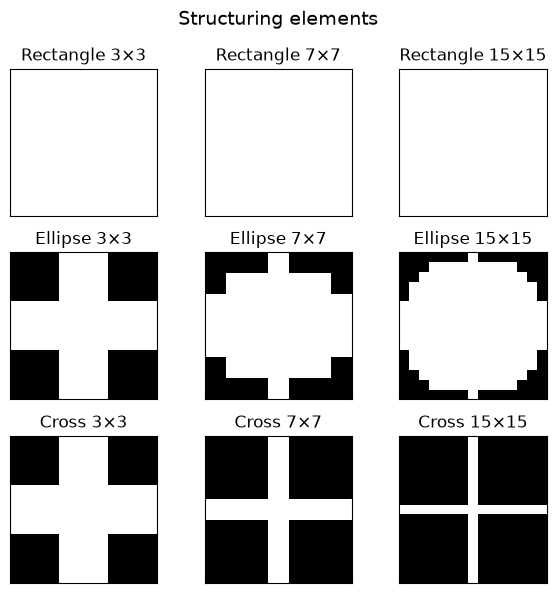

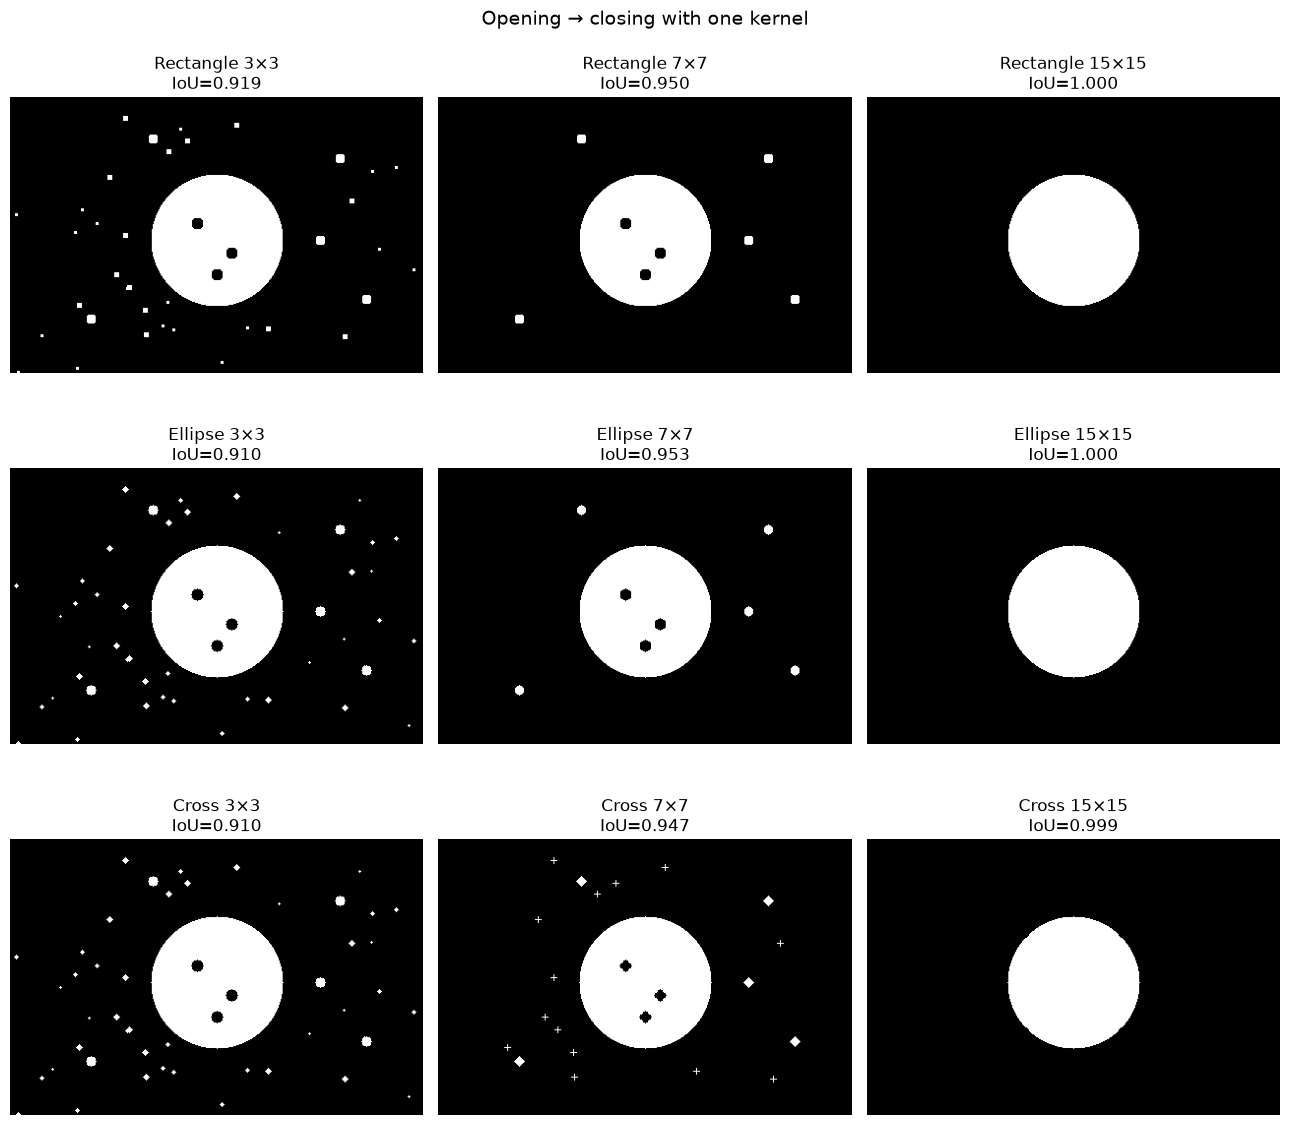

In [10]:
kernel_shapes = {
    "Rectangle": cv2.MORPH_RECT,
    "Ellipse": cv2.MORPH_ELLIPSE,
    "Cross": cv2.MORPH_CROSS,
}
kernel_sizes = (3, 7, 15)
kernel_experiments = {}

for shape_name, shape_code in kernel_shapes.items():
    for size in kernel_sizes:
        kernel = cv2.getStructuringElement(shape_code, (size, size))
        opened_mask = cv2.morphologyEx(hsv_mask, cv2.MORPH_OPEN, kernel)
        result_mask = cv2.morphologyEx(opened_mask, cv2.MORPH_CLOSE, kernel)
        kernel_experiments[(shape_name, size)] = (kernel, result_mask)

fig, axes = plt.subplots(3, 3, figsize=(6, 6))
for row, shape_name in enumerate(kernel_shapes):
    for column, size in enumerate(kernel_sizes):
        kernel, _ = kernel_experiments[(shape_name, size)]
        axes[row, column].imshow(kernel, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        axes[row, column].set_title(f"{shape_name} {size}×{size}")
        axes[row, column].set_xticks([])
        axes[row, column].set_yticks([])
fig.suptitle("Structuring elements", fontsize=14)
plt.tight_layout()

fig, axes = plt.subplots(3, 3, figsize=(13, 12))
for row, shape_name in enumerate(kernel_shapes):
    for column, size in enumerate(kernel_sizes):
        _, result_mask = kernel_experiments[(shape_name, size)]
        score = mask_iou(result_mask, ground_truth)
        axes[row, column].imshow(result_mask, cmap="gray", vmin=0, vmax=255)
        axes[row, column].set_title(f"{shape_name} {size}×{size}\nIoU={score:.3f}")
        axes[row, column].axis("off")
fig.suptitle("Opening → closing with one kernel", fontsize=14)
plt.tight_layout()

## 5. Connected components: from pixels to candidates

A connected component is a maximal group of foreground pixels linked under a neighborhood rule. With 4-connectivity, pixels connect through edges; with 8-connectivity, diagonals count too.

`connectedComponentsWithStats` returns a label image plus each component's bounding box, area, and centroid. Label 0 is the background. Morphology removes the tiniest confetti, but several deliberately stubborn orange blobs survive. We can reject those by area and optionally use width, height, aspect ratio, fill density, or shape measurements.

### What counts as touching?

The choice between 4- and 8-connectivity matters only at diagonal contacts. The tiny masks below make that rule visible before we return to the larger scene. Each nonzero color and printed number in a label image represents one component.

**Practice:** modify the slices to add gaps, diagonal bridges, and edge bridges. Predict the component counts before running the cell.

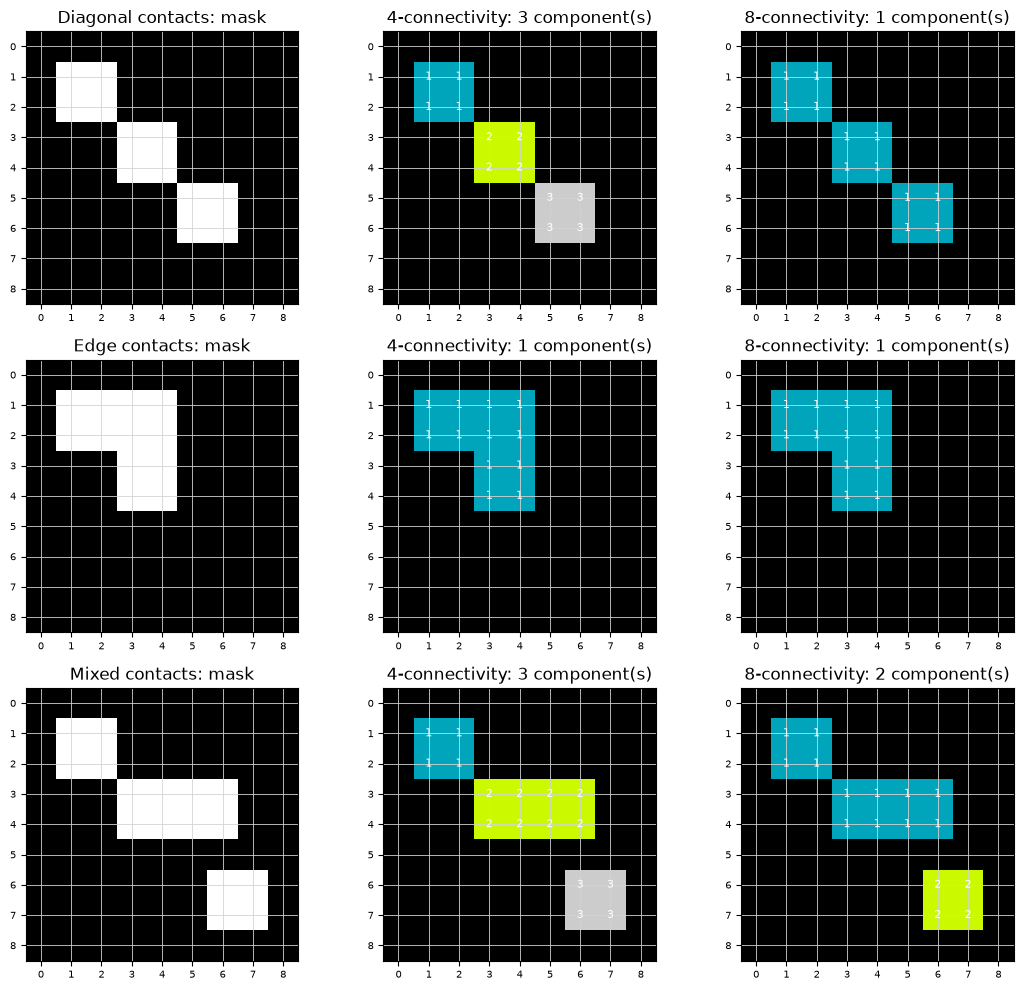

In [11]:
diagonal_touch = np.zeros((9, 9), dtype=np.uint8)
diagonal_touch[1:3, 1:3] = 255
diagonal_touch[3:5, 3:5] = 255
diagonal_touch[5:7, 5:7] = 255

edge_touch = np.zeros((9, 9), dtype=np.uint8)
edge_touch[1:3, 1:3] = 255
edge_touch[1:3, 3:5] = 255
edge_touch[3:5, 3:5] = 255

mixed_touch = np.zeros((9, 9), dtype=np.uint8)
mixed_touch[1:3, 1:3] = 255
mixed_touch[3:5, 3:5] = 255  # Diagonal contact with the first square.
mixed_touch[3:5, 5:7] = 255  # Edge contact with the second square.
mixed_touch[6:8, 6:8] = 255  # Mixed contact with the third square.

tiny_masks = {
    "Diagonal contacts": diagonal_touch,
    "Edge contacts": edge_touch,
    "Mixed contacts": mixed_touch,
}
fig, axes = plt.subplots(len(tiny_masks), 3, figsize=(11, 10))

for row, (name, mask) in enumerate(tiny_masks.items()):
    axes[row, 0].imshow(mask, cmap="gray", interpolation="nearest")
    axes[row, 0].set_title(f"{name}: mask")

    for column, connectivity in enumerate((4, 8), start=1):
        label_count, tiny_labels = cv2.connectedComponents(mask, connectivity=connectivity)
        component_count = label_count - 1  # Exclude background label 0.
        axes[row, column].imshow(tiny_labels, cmap="nipy_spectral", vmin=0, vmax=3, interpolation="nearest")
        axes[row, column].set_title(f"{connectivity}-connectivity: {component_count} component(s)")
        for y, x in np.argwhere(tiny_labels > 0):
            axes[row, column].text(x, y, str(tiny_labels[y, x]), ha="center", va="center", color="white", fontsize=8)

for ax in axes.flat:
    ax.set_xticks(range(9))
    ax.set_yticks(range(9))
    ax.grid(color="lightgray", linewidth=0.6)
    ax.tick_params(labelsize=7)
plt.tight_layout()

In [12]:
count, labels, stats, centroids = cv2.connectedComponentsWithStats(clean_mask, connectivity=8)
components = []
detections = []
minimum_area = 100

for label in range(1, count):
    x, y, width, height, area = stats[label]
    density = area / (width * height)
    component = {
        "label": label,
        "box": (x, y, width, height),
        "area": int(area),
        "density": float(density),
        "centroid": tuple(centroids[label]),
        "kept": bool(area >= minimum_area),
    }
    components.append(component)
    if area >= minimum_area:
        detections.append(component)

len(components), len(detections)

(6, 1)

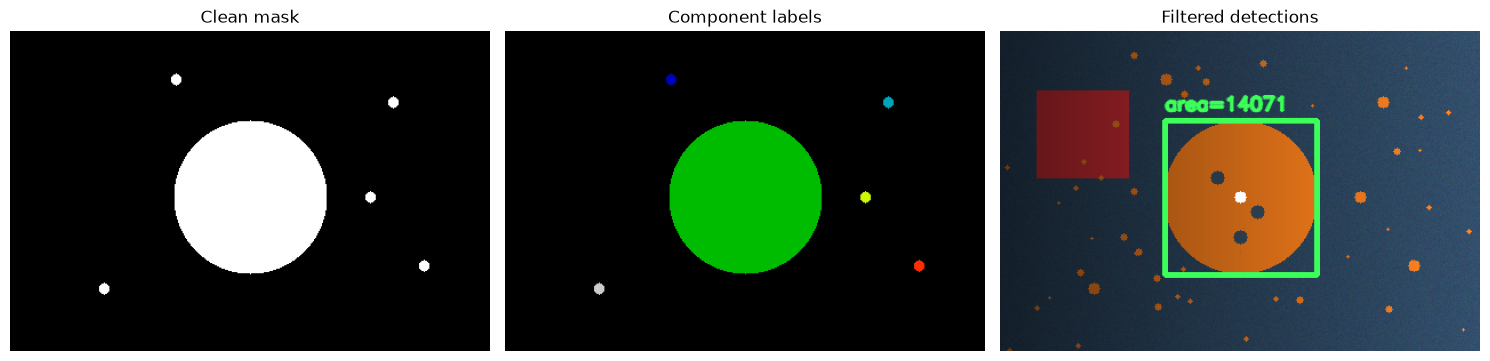

In [13]:
annotated = rgb.copy()
for detection in detections:
    x, y, width, height = detection["box"]
    cx, cy = np.round(detection["centroid"]).astype(int)
    cv2.rectangle(annotated, (x, y), (x + width, y + height), (60, 255, 90), 3)
    cv2.circle(annotated, (cx, cy), 5, (255, 255, 255), -1)
    cv2.putText(
        annotated,
        f"area={detection['area']}",
        (x, max(18, y - 9)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.55,
        (60, 255, 90),
        2,
        cv2.LINE_AA,
    )

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, image, title, cmap in zip(
    axes,
    [clean_mask, labels, annotated],
    ["Clean mask", "Component labels", "Filtered detections"],
    ["gray", "nipy_spectral", None],
):
    ax.imshow(image, cmap=cmap)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()

## 6. Illumination tests

A useful pipeline should be evaluated across conditions, not only on the image used to choose its thresholds. We keep both detectors fixed and vary global brightness. First, we test a moderate operating range—the kind of variation we hope the detector can tolerate.

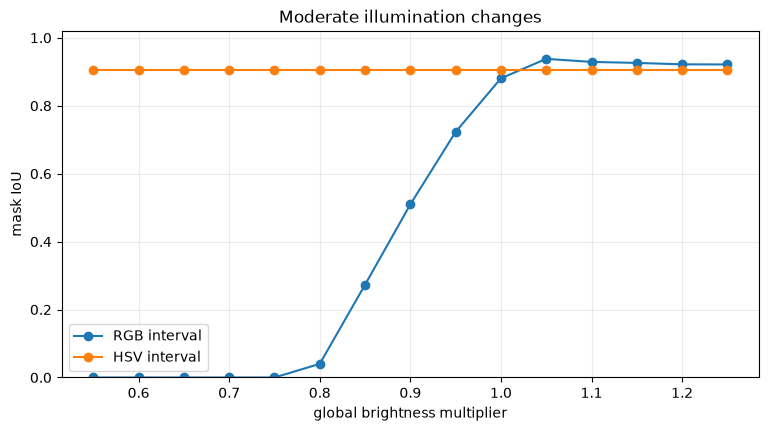

In [14]:
def evaluate_brightness(levels):
    rgb_scores = []
    hsv_scores = []
    for level in levels:
        test_rgb, test_ground_truth = make_scene(brightness=level)
        test_rgb_mask = cv2.inRange(test_rgb, rgb_lower, rgb_upper)
        test_hsv = cv2.cvtColor(test_rgb, cv2.COLOR_RGB2HSV)
        test_hsv_mask = cv2.inRange(test_hsv, hsv_lower, hsv_upper)
        rgb_scores.append(mask_iou(test_rgb_mask, test_ground_truth))
        hsv_scores.append(mask_iou(test_hsv_mask, test_ground_truth))
    return np.asarray(rgb_scores), np.asarray(hsv_scores)


def plot_brightness_test(levels, rgb_scores, hsv_scores, title):
    plt.figure(figsize=(9, 4.5))
    plt.plot(levels, rgb_scores, "o-", label="RGB interval")
    plt.plot(levels, hsv_scores, "o-", label="HSV interval")
    plt.xlabel("global brightness multiplier")
    plt.ylabel("mask IoU")
    plt.ylim(0, 1.02)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.title(title)
    plt.show()


operating_levels = np.linspace(0.55, 1.25, 15)
operating_rgb_scores, operating_hsv_scores = evaluate_brightness(operating_levels)
plot_brightness_test(
    operating_levels,
    operating_rgb_scores,
    operating_hsv_scores,
    "Moderate illumination changes",
)

### Experiment: keep turning the brightness knob

The first result may tempt us to say that HSV is unaffected by brightness. Let us challenge that conclusion by extending the range from near darkness to severe overexposure. This is a **stress test**, not a normal operating range.

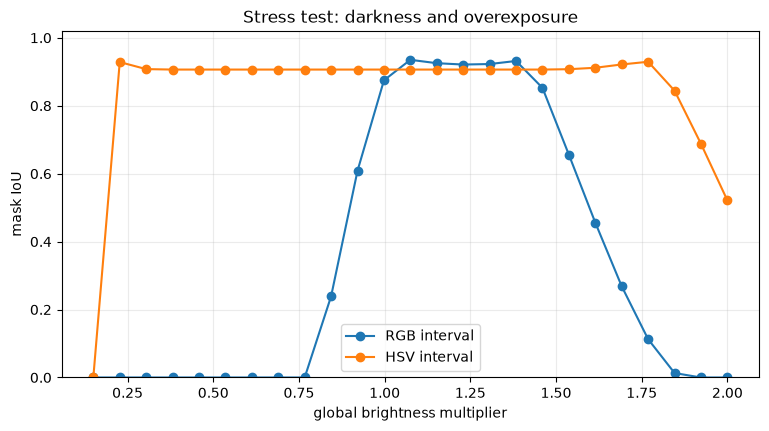

In [15]:
stress_levels = np.linspace(0.15, 2.0, 25)
stress_rgb_scores, stress_hsv_scores = evaluate_brightness(stress_levels)
plot_brightness_test(
    stress_levels,
    stress_rgb_scores,
    stress_hsv_scores,
    "Stress test: darkness and overexposure",
)

The two plots answer different questions. HSV is more stable across our moderate operating range because hue and saturation remain useful while value changes. Under extreme darkness or clipping, however, color information is weakened or destroyed and both methods fail. Do not conclude that HSV always wins: different tasks may favor Lab, YCrCb, normalized chromaticity, grayscale, or the original RGB values. Choose coordinates that make the relevant signal easier to separate.

### Quick reflection

- Why does HSV tolerate moderate brightness changes here but still fail at the extremes?
    - HSV separates color from brightness, so moderate brightness changes mostly affect value. In extreme darkness or clipping, useful color information is lost.
- Can morphology recover object pixels that thresholding genuinely removed, or only reshape the evidence that remains?
    - It can fill small gaps using nearby mask pixels, but it cannot recover the original evidence or restore an object that disappeared completely.
- Why can connected-component filtering count as object detection even though nothing was trained?
    - It groups foreground pixels into candidate objects, which we can filter by area, width, height, and other properties.
- Which assumption in this pipeline would a real photograph be most likely to break first?
    - Probably the assumption that the target has a stable, unique color. Lighting, shadows, and similar background colors can break the threshold first.

## Takeaway

A classical detector is a chain of explicit assumptions:

1. the target is separable in a chosen representation;
2. thresholding produces an imperfect but useful mask;
3. expected geometry can clean that mask;
4. connectivity groups pixels into candidate objects;
5. component statistics reject candidates that violate our expectations.

The pipeline is interpretable because every failure points toward an assumption. It is brittle for exactly the same reason.